# Method B — HOG + GLCM + RBF-SVM

This is the complete Method B experiment: load the B2 patch dataset, cache HOG+GLCM features, train the SVM, inspect patch classification, generate full-image confidence maps, choose the mask threshold on validation images after removing 8-connected components smaller than 2,560 pixels, then run the test set once.

Core algorithms remain in `src/method_b.py`. This notebook only orchestrates the experiment and presents its results. The test cells must be run only after the validation threshold has been frozen.

**Saved-result update:** Section 6 contains the completed validation/test area-filtering results, tables and visual comparisons. To repeat only postprocessing, run its four code cells in order; training and sliding-window inference are unnecessary.

In [ ]:
from pathlib import Path
import sys

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
assert (ROOT / 'src' / 'method_b.py').exists(), 'Start Jupyter in the repository or notebooks folder.'
sys.path.insert(0, str(ROOT))

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import classification_report, ConfusionMatrixDisplay

from src import config, data, evaluate, method_b, utils

utils.set_seed()
B2_DATASET = ROOT.parents[1] / 'Concrete Crack B2 32x32 Center 2x2'
CACHE_DIR = B2_DATASET / '_feature_cache'
MODEL_PATH = config.MODELS_DIR / 'method_b.joblib'
params = utils.load_params('B', method_b.DEFAULT_PARAMS)
split = data.load_split()
THRESHOLDS = np.round(np.arange(0.10, 0.91, 0.05), 2)
print('Dataset:', B2_DATASET)
print('Image split:', {name: len(ids) for name, ids in split.items()})
print('Parameters:', params)

## 1. Verify and inspect B2

Positive patches come from the fixed image-level split and have a ground-truth `2×2` crack region at their centre. Negative patches are the centre crops retained from B1. Expected totals are 28,000 train, 6,000 validation and 6,000 test patches.

In [2]:
EXPECTED = {'train': 14000, 'val': 3000, 'test': 3000}
dataset_rows = []
for split_name, per_class in EXPECTED.items():
    for class_name in ('Negative', 'Positive'):
        files = sorted((B2_DATASET / split_name / class_name).glob('*.png'))
        assert len(files) == per_class, (split_name, class_name, len(files))
        sample = utils.read_image(files[0])
        assert sample.shape == (32, 32, 3)
        dataset_rows.append({'split': split_name, 'class': class_name, 'patches': len(files)})
pd.DataFrame(dataset_rows)

,split,class,patches
0,train,Negative,14000
1,train,Positive,14000
2,val,Negative,3000
3,val,Positive,3000
4,test,Negative,3000
5,test,Positive,3000


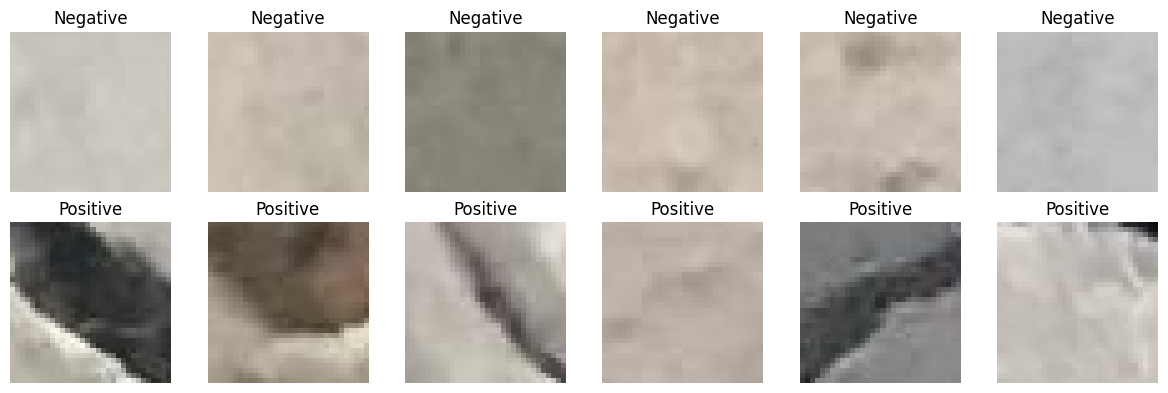

In [3]:
fig, axes = plt.subplots(2, 6, figsize=(12, 4))
for row, class_name in enumerate(('Negative', 'Positive')):
    files = sorted((B2_DATASET / 'train' / class_name).glob('*.png'))
    indices = np.random.default_rng(config.SEED + row).choice(len(files), 6, replace=False)
    for axis, index in zip(axes[row], indices):
        axis.imshow(utils.read_image(files[index]))
        axis.set_title(class_name)
        axis.axis('off')
plt.tight_layout()

## 2. Extract HOG + GLCM features

Feature arrays are cached beside the generated B2 dataset. Delete `_feature_cache` only when the feature definition changes.

In [4]:
LABELS = {'Negative': 0, 'Positive': 1}

def load_feature_split(split_name):
    cache_path = CACHE_DIR / f'hog_glcm_v1_{split_name}.npz'
    if cache_path.exists():
        cached = np.load(cache_path)
        print('Loaded', cache_path)
        return cached['features'], cached['labels']

    items = [(path, label)
             for class_name, label in LABELS.items()
             for path in sorted((B2_DATASET / split_name / class_name).glob('*.png'))]
    features = np.empty((len(items), 340), dtype=np.float32)
    labels = np.empty(len(items), dtype=np.uint8)
    for index, (path, label) in enumerate(items):
        features[index] = method_b.extract_features_b(utils.read_image(path))
        labels[index] = label
        if (index + 1) % 2000 == 0:
            print(f'{split_name}: {index + 1:,}/{len(items):,}')
    CACHE_DIR.mkdir(parents=True, exist_ok=True)
    np.savez_compressed(cache_path, features=features, labels=labels)
    return features, labels

X_train, y_train = load_feature_split('train')
X_val, y_val = load_feature_split('val')
print('Train:', X_train.shape, np.bincount(y_train))
print('Validation:', X_val.shape, np.bincount(y_val))

Loaded F:\bowen\UTS-study\sem3\image\Concrete Crack B2 32x32 Center 2x2\_feature_cache\hog_glcm_v1_train.npz
Loaded F:\bowen\UTS-study\sem3\image\Concrete Crack B2 32x32 Center 2x2\_feature_cache\hog_glcm_v1_val.npz
Train: (28000, 340) [14000 14000]
Validation: (6000, 340) [3000 3000]


## 3. Train the classifier

The fitted pipeline standardises the 340 HOG+GLCM features and trains the configured RBF-SVM. With 28,000 training patches this can take time.

In [5]:
with utils.timer() as training_time:
    model = method_b.fit_classifier_b(X_train, y_train, params)
method_b.save_model_b(model, MODEL_PATH)
print(f'Trained in {training_time["seconds"]:.1f} s')
print('Saved:', MODEL_PATH)

Trained in 362.5 s
Saved: F:\bowen\UTS-study\sem3\image\Github\crack-width-measurement\models\method_b.joblib


              precision    recall  f1-score   support

    Negative     0.9298    0.9763    0.9525      3000
    Positive     0.9751    0.9263    0.9501      3000

    accuracy                         0.9513      6000
   macro avg     0.9525    0.9513    0.9513      6000
weighted avg     0.9525    0.9513    0.9513      6000



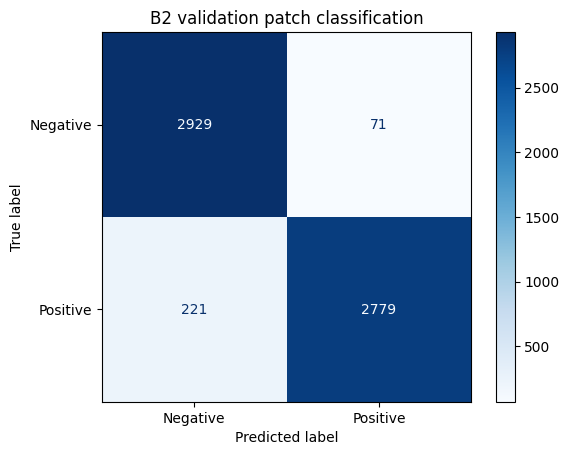

In [6]:
val_patch_prediction = model.predict(X_val)
print(classification_report(y_val, val_patch_prediction, target_names=['Negative', 'Positive'], digits=4))
ConfusionMatrixDisplay.from_predictions(y_val, val_patch_prediction, display_labels=['Negative', 'Positive'], cmap='Blues')
plt.title('B2 validation patch classification')
plt.show()

## 4. Validation confidence maps and threshold selection

Each full validation image is scanned once. Overlapping patch probabilities are aggregated by `method_b.segment_b` into an image-sized confidence map and saved under `results/B/val`. For every threshold, 8-connected regions smaller than `params['min_component_area']` (2,560 pixels) are removed before calculating Precision, Recall, Dice/F1 and IoU. Threshold selection and saved validation masks both use the saved 8-bit confidence maps, so rounding is consistent. This is the slowest stage.

In [ ]:
def strict_counts(prediction, reference):
    return (
        int(np.count_nonzero(prediction & reference)),
        int(np.count_nonzero(prediction & ~reference)),
        int(np.count_nonzero(~prediction & reference)),
    )

def metrics_from_triplet(tp, fp, fn):
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    return {
        'precision': precision,
        'recall': recall,
        'f1': 2 * tp / (2 * tp + fp + fn) if 2 * tp + fp + fn else 1.0,
        'iou': tp / (tp + fp + fn) if tp + fp + fn else 1.0,
    }

def validation_threshold_table():
    totals = {float(t): [0, 0, 0] for t in THRESHOLDS}
    for index, image_id in enumerate(split['val'], start=1):
        image, reference = data.load_pair(image_id)
        _, confidence = method_b.segment_b(image, model, params)
        utils.save_prob(confidence, utils.result_path('B', 'val', image_id, 'prob'))
        confidence = utils.read_prob(utils.result_path('B', 'val', image_id, 'prob'))
        for threshold in THRESHOLDS:
            prediction = method_b.mask_from_confidence_b(confidence, {**params, 'threshold': float(threshold)})
            counts = strict_counts(prediction, reference)
            totals[float(threshold)] = [a + b for a, b in zip(totals[float(threshold)], counts)]
        print(f'validation {index}/{len(split["val"])}: {image_id}')
    return pd.DataFrame([{'threshold': threshold, **metrics_from_triplet(*counts)}
                         for threshold, counts in totals.items()])

validation_thresholds = validation_threshold_table()
validation_thresholds

In [ ]:
best = validation_thresholds.loc[validation_thresholds['f1'].idxmax()]
params['threshold'] = float(best['threshold'])
utils.save_params('B', params)
config.EVAL_DIR.mkdir(parents=True, exist_ok=True)
validation_thresholds.to_csv(config.EVAL_DIR / 'method_b_validation_thresholds.csv', index=False)

for image_id in split['val']:
    confidence = utils.read_prob(utils.result_path('B', 'val', image_id, 'prob'))
    prediction = method_b.mask_from_confidence_b(confidence, params)
    utils.save_mask(prediction, utils.result_path('B', 'val', image_id))

print('Frozen validation-selected threshold:', params['threshold'])
display(best.to_frame('validation').T)
validation_thresholds.plot(x='threshold', y=['precision', 'recall', 'f1', 'iou'], ylim=(0, 1), grid=True, figsize=(8, 4))
plt.axvline(params['threshold'], color='black', linestyle='--')
plt.show()

In [ ]:
example_ids = split['val'][:3]
fig, axes = plt.subplots(len(example_ids), 4, figsize=(15, 4 * len(example_ids)))
for row, image_id in enumerate(example_ids):
    image, reference = data.load_pair(image_id)
    confidence = utils.read_prob(utils.result_path('B', 'val', image_id, 'prob'))
    prediction = method_b.mask_from_confidence_b(confidence, params)
    for axis, value, title, cmap in zip(
        axes[row],
        (image, reference, confidence, prediction),
        ('Image', 'Ground truth', 'Confidence map', f'Mask ≥ {params["threshold"]:.2f}'),
        (None, 'gray', 'magma', 'gray')):
        axis.imshow(value, cmap=cmap, vmin=0 if cmap else None, vmax=1 if cmap else None)
        axis.set_title(f'{image_id}: {title}')
        axis.axis('off')
plt.tight_layout()

## 5. Final test run

Run the remaining cells only after the model settings, validation-selected threshold and minimum component area are frozen. `method_b.segment_b` returns the filtered binary mask, so saved test masks and test metrics both include removal of 8-connected regions smaller than 2,560 pixels. Confidence maps remain unchanged. Test data must not be used for further tuning.

test: 2,000/6,000
test: 4,000/6,000
test: 6,000/6,000
              precision    recall  f1-score   support

    Negative     0.9206    0.9740    0.9466      3000
    Positive     0.9724    0.9160    0.9434      3000

    accuracy                         0.9450      6000
   macro avg     0.9465    0.9450    0.9450      6000
weighted avg     0.9465    0.9450    0.9450      6000



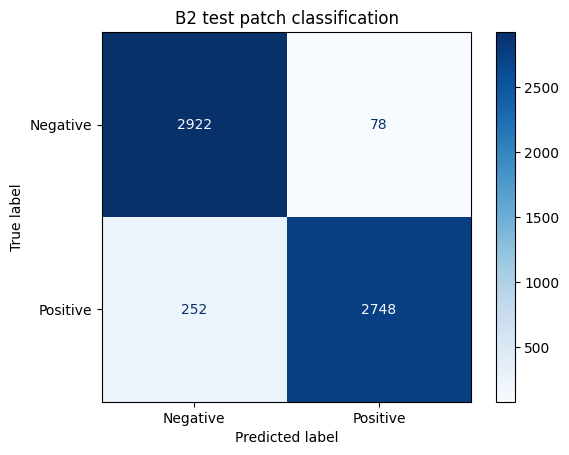

In [10]:
X_test, y_test = load_feature_split('test')
test_patch_prediction = model.predict(X_test)
print(classification_report(y_test, test_patch_prediction, target_names=['Negative', 'Positive'], digits=4))
ConfusionMatrixDisplay.from_predictions(y_test, test_patch_prediction, display_labels=['Negative', 'Positive'], cmap='Blues')
plt.title('B2 test patch classification')
plt.show()

In [ ]:
total_counts = {key: 0 for key in evaluate.COUNT_KEYS}
per_image_rows = []
for index, image_id in enumerate(split['test'], start=1):
    image, reference = data.load_pair(image_id)
    prediction, confidence = method_b.segment_b(image, model, params)
    utils.save_prob(confidence, utils.result_path('B', 'test', image_id, 'prob'))
    utils.save_mask(prediction, utils.result_path('B', 'test', image_id))
    metrics = evaluate.seg_metrics(prediction, reference)
    per_image_rows.append({'image_id': image_id, **metrics})
    for key in evaluate.COUNT_KEYS:
        total_counts[key] += metrics[key]
    print(f'test {index}/{len(split["test"])}: {image_id}')

test_summary = evaluate.metrics_from_counts(total_counts)
test_rows = pd.DataFrame(per_image_rows)
test_rows.to_csv(config.EVAL_DIR / 'method_b_test_per_image.csv', index=False)
pd.DataFrame([test_summary], index=['Method B test'])

## 6. Postprocessing results from saved predictions

Read the existing validation and test binary masks, remove 8-connected components smaller than **2,560 pixels**, and compare the results. The saved source masks use threshold **0.90**. No model training or sliding-window inference is needed.

The area setting is fixed from the validation experiment. Test results below are a postprocessing re-evaluation of existing predictions, not a new independent final test. Source masks, confidence maps and the original ZIP are preserved.

**How to run only this section:** run the next four code cells in order, starting with the imports below. They are self-contained and do not require Sections 1-5. Existing outputs are already included. Running the whole notebook also runs the original training and inference stages.

In [1]:
from pathlib import Path
import json
import sys

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
assert (ROOT / 'src' / 'method_b.py').exists(), 'Open this notebook from the project folder.'
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from src import config, data, evaluate, method_b, utils

MIN_AREA = 2560
split = data.load_split()
OUTPUT = config.RESULTS_DIR / 'B' / f'postprocessed_area{MIN_AREA}'
reference_paths = {p.stem: p for p in config.MASK_DIR.iterdir() if p.suffix.lower() in config.IMAGE_EXTS}
for split_name in ('val', 'test'):
    for image_id in split[split_name]:
        assert utils.result_path('B', split_name, image_id).exists(), (split_name, image_id)
        assert image_id in reference_paths, image_id
print('Validation masks:', len(split['val']))
print('Test masks:', len(split['test']))
print('Keep components with area >=', MIN_AREA, 'pixels; connectivity = 8')
print('Output:', OUTPUT)

Validation masks: 69
Test masks: 69
Keep components with area >= 2560 pixels; connectivity = 8
Output: F:\bowen\UTS-study\sem3\image\Github\crack-width-measurement\results\B\postprocessed_area2560


### 6.1 Filter saved masks and compare metrics

Every saved mask is filtered by the same core function used by `segment_b`. Scores are micro-averaged by summing pixel counts across each split. Tolerance metrics allow a distance of 2 pixels. The confidence maps are unchanged and remain in their original folders.

In [2]:
summary_rows = []
change_rows = []
per_image_rows = []
with utils.timer() as elapsed:
    for split_name in ('val', 'test'):
        totals = {stage: dict.fromkeys(evaluate.COUNT_KEYS, 0) for stage in ('raw', 'filtered')}
        output_dir = OUTPUT / split_name
        output_dir.mkdir(parents=True, exist_ok=True)
        for index, image_id in enumerate(split[split_name], 1):
            raw = utils.read_mask(utils.result_path('B', split_name, image_id))
            reference = utils.read_mask(reference_paths[image_id])
            filtered = method_b.postprocess_mask_b(raw, MIN_AREA)
            removed = int(np.count_nonzero(raw & ~filtered))
            raw_counts = evaluate.confusion_counts(raw, reference)
            filtered_counts = evaluate.confusion_counts(filtered, reference) if removed else raw_counts
            for stage, counts in (('raw', raw_counts), ('filtered', filtered_counts)):
                for key in evaluate.COUNT_KEYS:
                    totals[stage][key] += counts[key]
                per_image_rows.append({'split': split_name, 'image_id': image_id, 'stage': stage, **evaluate.metrics_from_counts(counts)})
            change_rows.append({'split': split_name, 'image_id': image_id, 'removed_pixels': removed,
                                'removed_true_crack_pixels': int(np.count_nonzero(raw & ~filtered & reference)),
                                'removed_false_positive_pixels': int(np.count_nonzero(raw & ~filtered & ~reference))})
            utils.save_mask(filtered, output_dir / f'{image_id}.png')
            if index % 20 == 0 or index == len(split[split_name]):
                print(f'{split_name}: {index}/{len(split[split_name])}', flush=True)
        summary_rows.extend({'split': split_name, 'stage': stage, **evaluate.metrics_from_counts(counts)}
                            for stage, counts in totals.items())

summary = pd.DataFrame(summary_rows)
changes = pd.DataFrame(change_rows)
summary.to_csv(OUTPUT / 'summary.csv', index=False)
changes.to_csv(OUTPUT / 'removed_pixels.csv', index=False)
pd.DataFrame(per_image_rows).to_csv(OUTPUT / 'per_image.csv', index=False)
(OUTPUT / 'settings.json').write_text(json.dumps({'min_component_area': MIN_AREA, 'connectivity': 8,
    'source': 'existing binary masks; original threshold 0.90', 'tolerance_px': config.TOLERANCE_PX}, indent=2), encoding='utf-8')
print(f'Completed in {elapsed["seconds"]:.1f} seconds')
display(summary.set_index(['split', 'stage']).round(6))

val: 20/69


val: 40/69


val: 60/69


val: 69/69


test: 20/69


test: 40/69


test: 60/69


test: 69/69


Completed in 66.1 seconds


precision    recall        f1       iou  tol_precision  \
split stage                                                              
val   raw        0.685253  0.685570  0.685412  0.521389       0.750982   
      filtered   0.724792  0.659593  0.690657  0.527484       0.792194   
test  raw        0.687289  0.675876  0.681535  0.516915       0.754498   
      filtered   0.728415  0.653394  0.688868  0.525399       0.796656   

                tol_recall    tol_f1  
split stage                           
val   raw         0.746362  0.748665  
      filtered    0.714074  0.751108  
test  raw         0.734503  0.744367  
      filtered    0.706810  0.749049

Change in percentage points: filtered minus raw


,precision,recall,f1,iou,tol_precision,tol_recall,tol_f1
split,,,,,,,
val,3.954,-2.598,0.525,0.609,4.121,-3.229,0.244
test,4.113,-2.248,0.733,0.848,4.216,-2.769,0.468


Removed pixels, including losses of true crack pixels:


,removed_pixels,removed_true_crack_pixels,removed_false_positive_pixels
split,,,
test,1005056,261566,743490
val,1011712,290668,721044


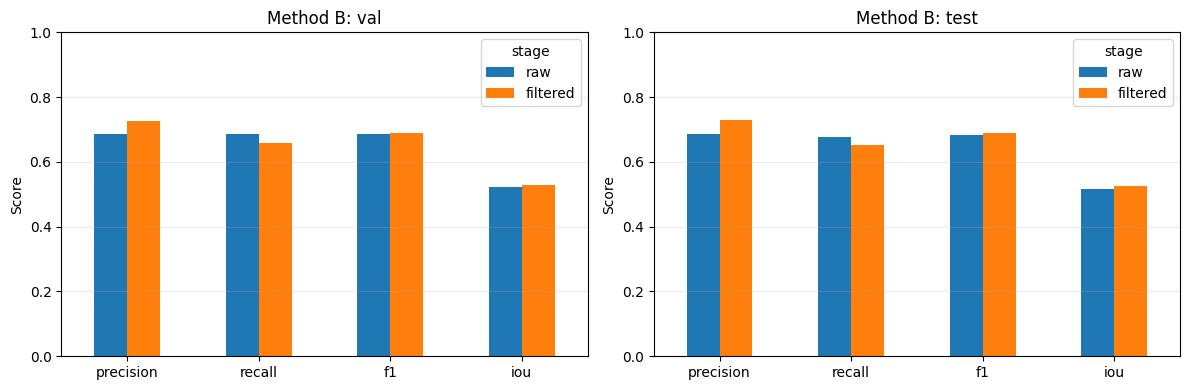

In [3]:
metrics = ['precision', 'recall', 'f1', 'iou', 'tol_precision', 'tol_recall', 'tol_f1']
delta = (summary[summary.stage == 'filtered'].set_index('split')[metrics]
         - summary[summary.stage == 'raw'].set_index('split')[metrics]) * 100
print('Change in percentage points: filtered minus raw')
display(delta.round(3))
print('Removed pixels, including losses of true crack pixels:')
display(changes.groupby('split')[['removed_pixels', 'removed_true_crack_pixels', 'removed_false_positive_pixels']].sum())
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for axis, split_name in zip(axes, ('val', 'test')):
    summary[summary.split == split_name].set_index('stage')[metrics[:4]].T.plot.bar(ax=axis, ylim=(0, 1), rot=0)
    axis.set_title(f'Method B: {split_name}')
    axis.set_ylabel('Score')
    axis.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

### 6.2 Visual comparison

For each split, show the two images with the most pixels removed. These are deliberately selected examples of the largest changes, not representative random examples. Filtering removes whole components; it does not thin or erode retained cracks.

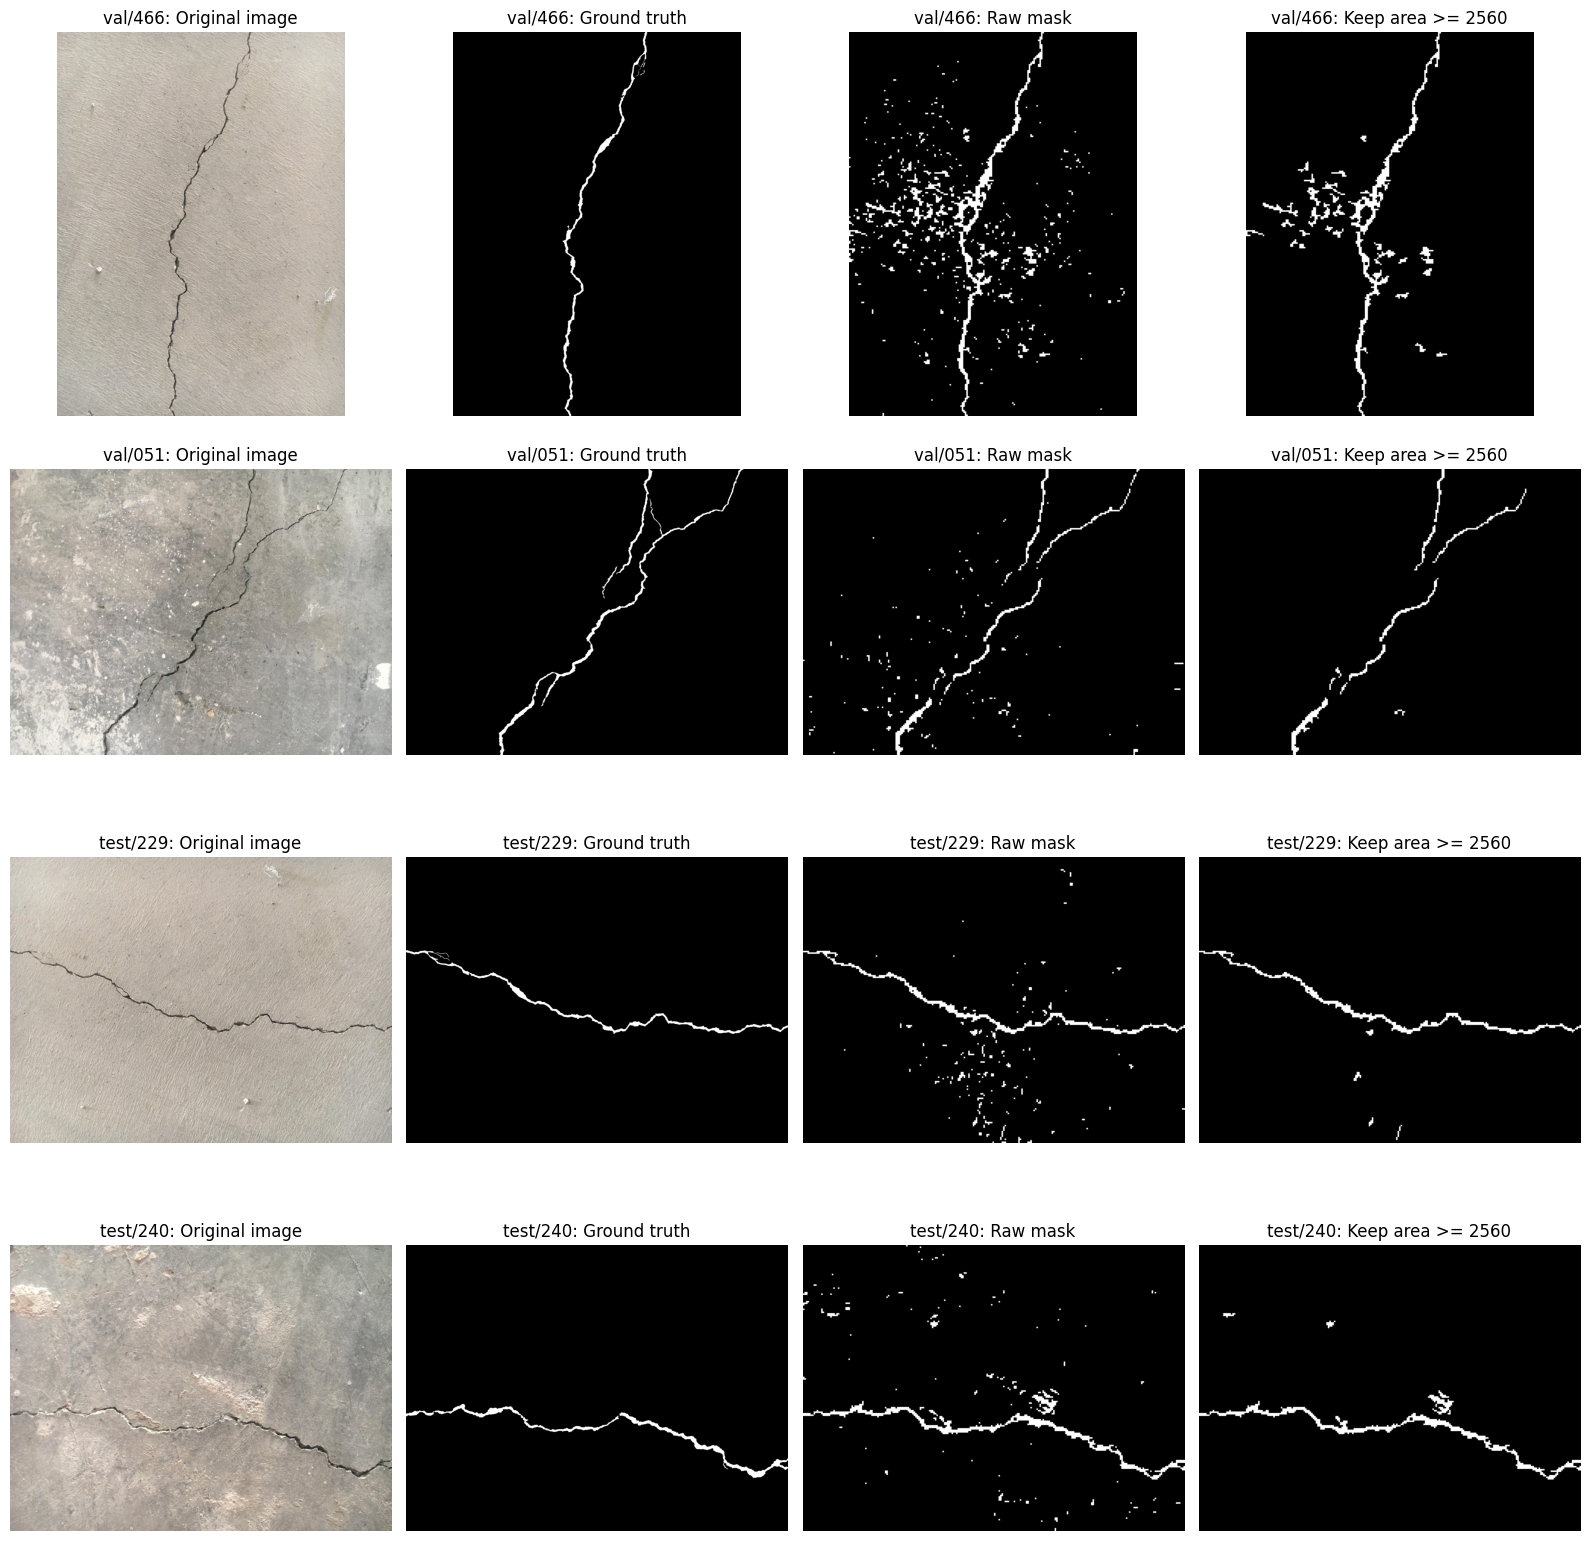

Filtered masks and evaluation tables: F:\bowen\UTS-study\sem3\image\Github\crack-width-measurement\results\B\postprocessed_area2560


In [4]:
examples = pd.concat([changes[changes.split == name].nlargest(2, 'removed_pixels') for name in ('val', 'test')])
fig, axes = plt.subplots(len(examples), 4, figsize=(16, 4 * len(examples)), squeeze=False)
for row, entry in enumerate(examples.itertuples(index=False)):
    image, reference = data.load_pair(entry.image_id)
    raw = utils.read_mask(utils.result_path('B', entry.split, entry.image_id))
    filtered = utils.read_mask(OUTPUT / entry.split / f'{entry.image_id}.png')
    for axis, value, title in zip(axes[row], (image, reference, raw, filtered),
                                 ('Original image', 'Ground truth', 'Raw mask', f'Keep area >= {MIN_AREA}')):
        axis.imshow(value, cmap='gray' if value.ndim == 2 else None)
        axis.set_title(f'{entry.split}/{entry.image_id}: {title}')
        axis.axis('off')
plt.tight_layout()
plt.show()
print('Filtered masks and evaluation tables:', OUTPUT)

## Interpretation notes

The confidence map has full image dimensions, but it is produced by aggregating overlapping patch probabilities rather than by an independent classifier at every pixel. The B2 positive labels have an exact central `2×2` crack core; the reused B1 negatives retain patch-level provenance. Report patch-classification and full-image segmentation results separately.